In [62]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import sys
from torch.utils.tensorboard import SummaryWriter

In [63]:
writer = SummaryWriter('runs/exp1')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [64]:
input_size = 784
hidden_size = 100
num_classes = 10
num_epochs = 2
batch_size = 100
learning_rate = 0.001

In [65]:
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())

test_dataset = torchvision.datasets.MNIST(root='./data', train=False,  transform=transforms.ToTensor())

test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle = True, num_workers=0)


In [66]:
samples, labels = next(iter(train_loader))
print(samples.shape, labels.shape)

torch.Size([100, 1, 28, 28]) torch.Size([100])


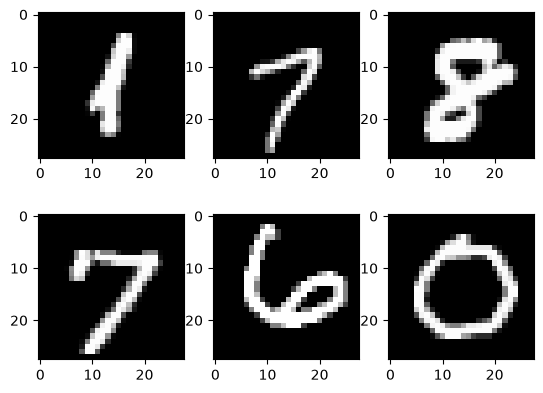

In [67]:
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(samples[i][0], cmap='gray')
    
img_grid = torchvision.utils.make_grid(samples)
writer.add_image('mnist_images', img_grid)

In [68]:
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(NeuralNet, self).__init__()
        self.l1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.l2 = nn.Linear(hidden_size, num_classes)
        
    def forward(self, x):
        out = self.l1(x)
        out = self.relu(out)
        out = self.l2(out)
        return out
    
model = NeuralNet(input_size, hidden_size, num_classes).to(device)

In [69]:
criterian =nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [70]:
writer.add_graph(model, samples.reshape(-1, 28*28).to(device))

In [71]:
running_loss = 0.0
running_correct = 0

In [72]:
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        loss = criterian(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predictions = torch.max(outputs, 1)
        running_correct = (predictions == labels).sum().item()

        
        if (i+1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}')
            writer.add_scalar('training loss', running_loss/100, epoch * len(train_loader)+i)
            writer.add_scalar('accuracy ', running_correct/100, epoch * len(train_loader)+i)
            running_loss = 0.0
            running_correct = 0
            writer.close()

Epoch [1/2], Step [100/600], Loss: 0.2561
Epoch [1/2], Step [200/600], Loss: 0.1640
Epoch [1/2], Step [300/600], Loss: 0.1024
Epoch [1/2], Step [400/600], Loss: 0.0669
Epoch [1/2], Step [500/600], Loss: 0.1284
Epoch [1/2], Step [600/600], Loss: 0.0838
Epoch [2/2], Step [100/600], Loss: 0.0769
Epoch [2/2], Step [200/600], Loss: 0.1881
Epoch [2/2], Step [300/600], Loss: 0.1071
Epoch [2/2], Step [400/600], Loss: 0.0663
Epoch [2/2], Step [500/600], Loss: 0.0896
Epoch [2/2], Step [600/600], Loss: 0.2881


In [73]:
with torch.no_grad():
    n_correct = 0
    n_samples = 0
    for images, labels in test_loader:
        images = images.reshape(-1, 28*28).to(device)
        labels = labels.to(device)
        outputs = model(images)
        
        _, predictions = torch.max(outputs, 1)
        n_samples += labels.size(0)
        n_correct += (predictions == labels).sum().item()
        
    acc = 100.0 * n_correct / n_samples
    print(f'Accuracy of the network on the 10000 test images: {acc} %')
        

Accuracy of the network on the 10000 test images: 96.0 %
